# Progetto finale - parte 1

## Librerie

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Setup e caricamento dati

In [6]:
# Impostazioni di visualizzazione
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

# Caricamento dataset
df = pd.read_csv('Fashion_data_Final_Project.csv')

df.shape

(999, 11)

## Panoramica generale e controllo qualità

In [8]:
# Prime righe del dataset
df.head()

,user_uuid,category,designer_id,language,level,country,purchase_date,platform,item_id,stars,subscription_date
0,183,belt,120,en,cheap,uk,13-7-2022,android,3521,1,20-8-2021
1,134,underwear,102,it,cheap,it,2-5-2023,android,6239,2,20-11-2022
2,158,belt,106,it,cheap,it,6-8-2021,pc,3618,3,18-3-2020
3,82,shoes,102,it,premium,it,18-7-2023,android,5281,4,21-1-2022
4,201,shoes,113,en,average,uk,7-5-2023,android,5260,1,25-11-2022


In [9]:
# Info generali: tipi di dato e valori non nulli per colonna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_uuid          999 non-null    int64 
 1   category           999 non-null    object
 2   designer_id        999 non-null    int64 
 3   language           999 non-null    object
 4   level              999 non-null    object
 5   country            999 non-null    object
 6   purchase_date      999 non-null    object
 7   platform           999 non-null    object
 8   item_id            999 non-null    int64 
 9   stars              999 non-null    int64 
 10  subscription_date  999 non-null    object
dtypes: int64(4), object(7)
memory usage: 86.0+ KB


In [10]:
# Valori mancanti per colonna
df.isna().sum()

user_uuid            0
category             0
designer_id          0
language             0
level                0
country              0
purchase_date        0
platform             0
item_id              0
stars                0
subscription_date    0
dtype: int64

In [11]:
# Righe duplicate (identiche su tutte le colonne)
df.duplicated().sum()

0

Non ci sono calori nulli o rughe duplicate.

In [13]:
# Statistiche descrittive per le colonne numeriche
df.describe()

,user_uuid,designer_id,item_id,stars
count,999.000000,999.000000,999.000000,999.000000
mean,126.206206,110.769770,4032.721722,3.013013
std,68.581911,6.623049,2266.843497,1.415216
min,1.000000,100.000000,26.000000,1.000000
25%,69.000000,105.000000,2248.000000,2.000000
50%,128.000000,111.000000,3662.000000,3.000000
75%,183.500000,116.000000,5972.500000,4.000000
max,245.000000,122.000000,11000.000000,5.000000


In [14]:
# Valori unici per ciascuna colonna categorica
for col in ['category', 'language', 'level', 'country', 'platform']:
    print(f"{col}: {df[col].nunique()} valori unici -> {sorted(df[col].unique())}")

category: 7 valori unici -> ['activewear', 'belt', 'bottom', 'dress', 'shirt', 'shoes', 'underwear']
language: 3 valori unici -> ['en', 'fr', 'it']
level: 3 valori unici -> ['average', 'cheap', 'premium']
country: 3 valori unici -> ['fr', 'it', 'uk']
platform: 3 valori unici -> ['android', 'apple', 'pc']


In [15]:
# Quanti utenti, designer e item unici
print("Utenti unici:", df['user_uuid'].nunique())
print("Designer unici:", df['designer_id'].nunique())
print("Item unici:", df['item_id'].nunique(), "su", len(df), "righe totali")

Utenti unici: 241
Designer unici: 23
Item unici: 901 su 999 righe totali


Si nota che il dataset contiene 999 vendite ma solo 901 valori unici di item_id (98 duplicati). Si procede ad un'analisi più approfondita di questi duplicati.

In [17]:
# Isola le righe che condividono lo stesso item_id
duplicated_items = df[df.duplicated(subset='item_id', keep=False)].sort_values('item_id')

# Per ogni item_id duplicato, conta quante categorie/designer/utenti diversi compaiono
check_duplicates = duplicated_items.groupby('item_id').agg(
    n_categorie=('category', 'nunique'),
    n_designer=('designer_id', 'nunique'),
    n_utenti=('user_uuid', 'nunique'),
    n_occorrenze=('item_id', 'count')
)

check_duplicates.head(10)

,n_categorie,n_designer,n_utenti,n_occorrenze
item_id,,,,
33,1,2,2,2
310,1,2,2,2
320,1,2,2,2
322,1,2,2,2
335,1,2,2,2
336,1,2,2,2
360,1,2,2,2
389,1,2,2,2
393,1,2,2,2


In [18]:
# Esempio concreto: un item_id duplicato nel dettaglio
esempio_id = check_duplicates.index[0]
df[df['item_id'] == esempio_id]

,user_uuid,category,designer_id,language,level,country,purchase_date,platform,item_id,stars,subscription_date
299,243,belt,100,en,cheap,uk,19-9-2021,apple,33,1,24-8-2020
404,33,belt,119,fr,cheap,fr,20-3-2023,android,33,5,2-7-2022


In [19]:
# Quanti item_id duplicati hanno effettivamente categoria E/O designer diversi?
diversi = check_duplicates[(check_duplicates['n_categorie'] > 1) | (check_duplicates['n_designer'] > 1)]
print(f"Item_id duplicati con categoria o designer diversi: {len(diversi)} su {len(check_duplicates)} totali")

Item_id duplicati con categoria o designer diversi: 90 su 91 totali


Analizzando questi duplicati, si osserva che righe con lo stesso item_id presentano spesso categoria e/o designer differenti: questo indica che non si tratta dello stesso articolo rivenduto più volte, ma di una probabile collisione nella generazione degli identificativi prodotto. Di conseguenza, **item_id non può essere usato come chiave univoca** per contare gli articoli distinti. Per le analisi a livello di prodotto si farà riferimento alla combinazione di più colonne (es. categoria + designer) oppure si lavorerà direttamente a livello di riga/vendita.

## Pulizia delle date e feature engineering
In questo paragrafo:
- Conversione delle date con il formato '%d-%m-%Y' (specificarlo esplicitamente evita ambiguità ed è più veloce del parsing automatico di pandas).
- Il controllo di coerenza verifica che nessuna vendita risulti antecedente all'iscrizione dell'utente.
- purchase_year, purchase_month, purchase_weekday serviranno nella fase successiva per l'analisi dei trend temporali (es. vendite per mese, stagionalità, giorno della settimana più attivo).
- purchase_year_month (tipo Period) è comodo per aggregare per mese o anno mantenendo l'ordine cronologico nei grafici.
- account_tenure_days/account_tenure_months misurano da quanto tempo un utente è iscritto quando effettua una vendita: serve per capire se gli utenti più fedeli vendono di più o vendono articoli di maggior valore.

In [22]:
# Conversione delle colonne data (formato gg-mm-aaaa)
df['purchase_date'] = pd.to_datetime(df['purchase_date'], format='%d-%m-%Y')
df['subscription_date'] = pd.to_datetime(df['subscription_date'], format='%d-%m-%Y')

df[['purchase_date', 'subscription_date']].dtypes

purchase_date        datetime64[ns]
subscription_date    datetime64[ns]
dtype: object

In [23]:
# Controllo di coerenza: nessuna vendita dovrebbe avvenire prima dell'iscrizione
righe_incoerenti = df[df['purchase_date'] < df['subscription_date']]
print(f"Righe con vendita precedente all'iscrizione: {len(righe_incoerenti)}")

Righe con vendita precedente all'iscrizione: 0


In [24]:
# Feature temporali legate alla vendita
df['purchase_year'] = df['purchase_date'].dt.year
df['purchase_month'] = df['purchase_date'].dt.month
df['purchase_weekday'] = df['purchase_date'].dt.day_name()
df['purchase_year_month'] = df['purchase_date'].dt.to_period('M')

In [25]:
# Anzianità dell'account al momento della vendita (in giorni e in mesi)
df['account_tenure_days'] = (df['purchase_date'] - df['subscription_date']).dt.days
df['account_tenure_months'] = (df['account_tenure_days'] / 30.44).round(1)

df[['subscription_date', 'purchase_date', 'account_tenure_days', 'account_tenure_months']].head()

,subscription_date,purchase_date,account_tenure_days,account_tenure_months
0,2021-08-20,2022-07-13,327,10.7
1,2022-11-20,2023-05-02,163,5.4
2,2020-03-18,2021-08-06,506,16.6
3,2022-01-21,2023-07-18,543,17.8
4,2022-11-25,2023-05-07,163,5.4


In [26]:
# Statistiche rapide sull'anzianità
df['account_tenure_days'].describe()

count     999.000000
mean      558.029029
std       287.826205
min        10.000000
25%       346.000000
50%       509.000000
75%       751.000000
max      1395.000000
Name: account_tenure_days, dtype: float64

## Analisi univariata delle variabili categoriche
Ora viene studiata la distribuzione di ciascuna variabile categorica per capire la composizione generale del dataset: quali categorie di prodotto, fasce di prezzo, paesi, lingue e piattaforme sono più rappresentate.

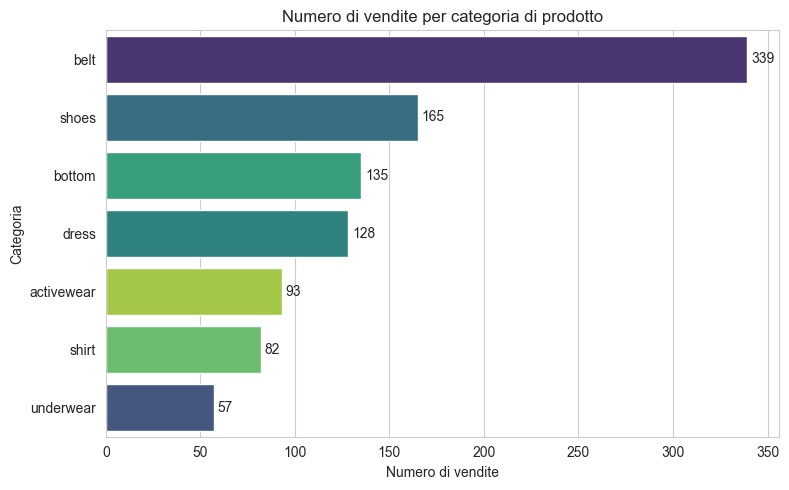

In [28]:
# Distribuzione delle vendite per categoria di prodotto
plt.figure(figsize=(8, 5))
order = df['category'].value_counts().index
ax = sns.countplot(data=df, y='category', order=order, hue='category', palette='viridis', legend=False)

# Aggiunta del conteggio esatto alla fine di ogni barra
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Numero di vendite per categoria di prodotto')
plt.xlabel('Numero di vendite')
plt.ylabel('Categoria')
plt.tight_layout()
plt.show()

In [29]:
# Tabella riassuntiva: conteggio e percentuale per categoria
category_summary = df['category'].value_counts().to_frame(name='conteggio')
category_summary['percentuale'] = (category_summary['conteggio'] / len(df) * 100).round(1)

category_summary

,conteggio,percentuale
category,,
belt,339,33.9
shoes,165,16.5
bottom,135,13.5
dress,128,12.8
activewear,93,9.3
shirt,82,8.2
underwear,57,5.7


Il countplot per category mostra subito quali tipi di capi vengono rivenduti più spesso sulla piattaforma. Questo permette di rispondere alla domanda:"quali prodotti hanno avuto più successo?"

In un marketplace di abbigliamento second-hand ci si aspetterebbe una prevalenza di capi come shirt o shoes, non di accessori come le cinture.

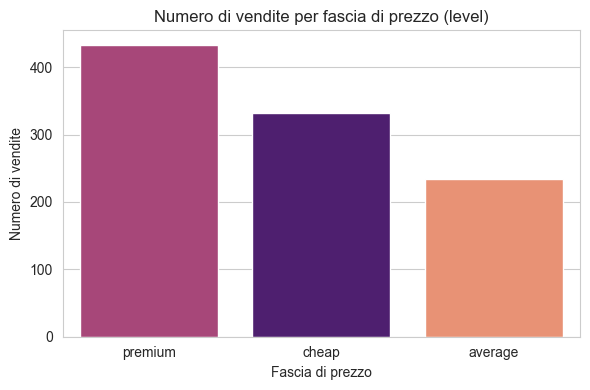

In [31]:
# Distribuzione delle vendite per fascia di prezzo (level)
plt.figure(figsize=(6, 4))
order = df['level'].value_counts().index
sns.countplot(data=df, x='level', order=order, hue='level', palette='magma', legend=False)
plt.title('Numero di vendite per fascia di prezzo (level)')
plt.xlabel('Fascia di prezzo')
plt.ylabel('Numero di vendite')
plt.tight_layout()
plt.show()

Il grafico su level mostra il mix tra articoli economici/medi/premium: utile per capire il posizionamento generale del marketplace.

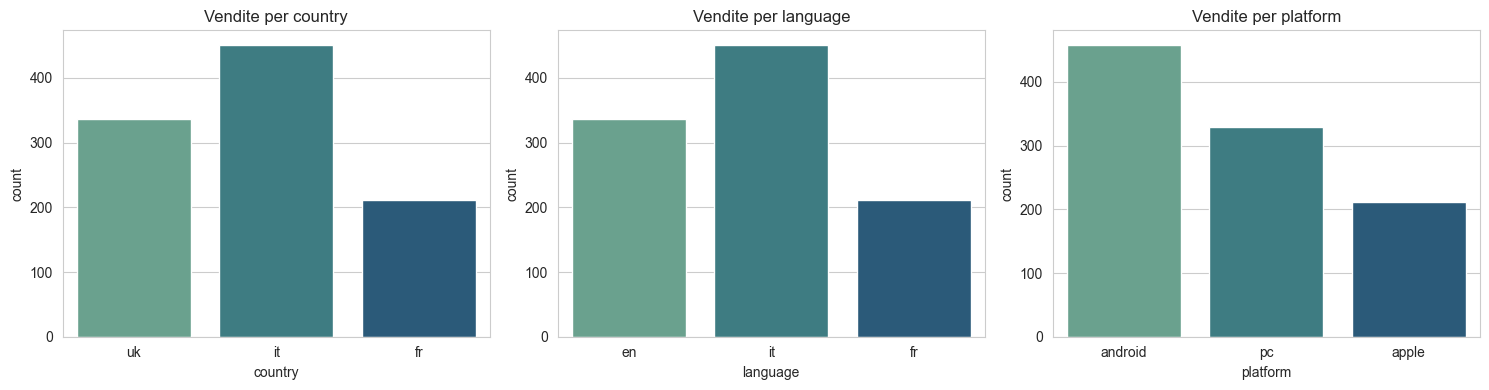

In [33]:
# Distribuzione per country, language e platform (in un'unica figura con subplot)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x='country', hue='country', ax=axes[0], palette='crest', legend=False)
axes[0].set_title('Vendite per country')

sns.countplot(data=df, x='language', hue='language', ax=axes[1], palette='crest', legend=False)
axes[1].set_title('Vendite per language')

sns.countplot(data=df, x='platform', hue='platform', ax=axes[2], palette='crest', legend=False)
axes[2].set_title('Vendite per platform')

plt.tight_layout()
plt.show()

Il risultato mostra una corrispondenza 1 a 1 perfetta tra i primi 2 plot: tutti gli utenti UK parlano inglese, tutti gli utenti IT parlano italiano, tutti gli utenti FR parlano francese, zero eccezioni. Sembra che language sia ridondante rispetto a country in questo dataset, sono la stessa informazione codificata due volte.
Se fossero due campi indipendenti, ci si aspetterebbe una quota di utenti che comprano in inglese pur non essendo madrelingua.


Il terzo plot non è sorprendente, gli acquisti vengono effettuati soprattutto da telefono e Android è il sistema operativo più diffuso.

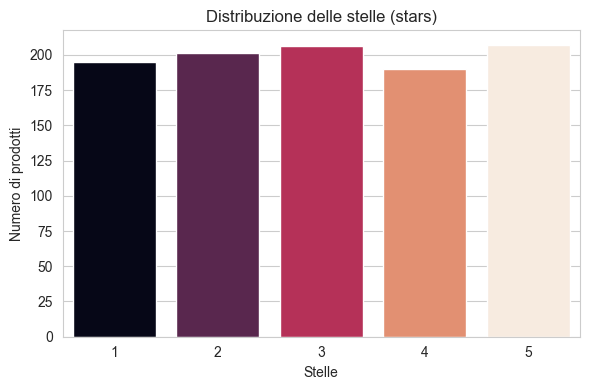

count    999.000000
mean       3.013013
std        1.415216
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        5.000000
Name: stars, dtype: float64


In [35]:
# Distribuzione delle stelle (stars) assegnate ai prodotti
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='stars', hue='stars', palette='rocket', legend=False)
plt.title('Distribuzione delle stelle (stars)')
plt.xlabel('Stelle')
plt.ylabel('Numero di prodotti')
plt.tight_layout()
plt.show()

print(df['stars'].describe())

La distribuzione di stars è importante: se è molto sbilanciata verso valori alti o bassi, dice qualcosa sulla qualità percepita generale. Verrà usata anche per capire cosa contribuisce al successo di un prodotto.

La distribuzione è quasi perfettamente uniforme (ognuna vicina al 20%). Di solito le recensioni online reali seguono una distribuzione a "J" o comunque skewed verso l'alto, perché chi è soddisfatto compra di più e chi ha avuto un problema serio è la minoranza.

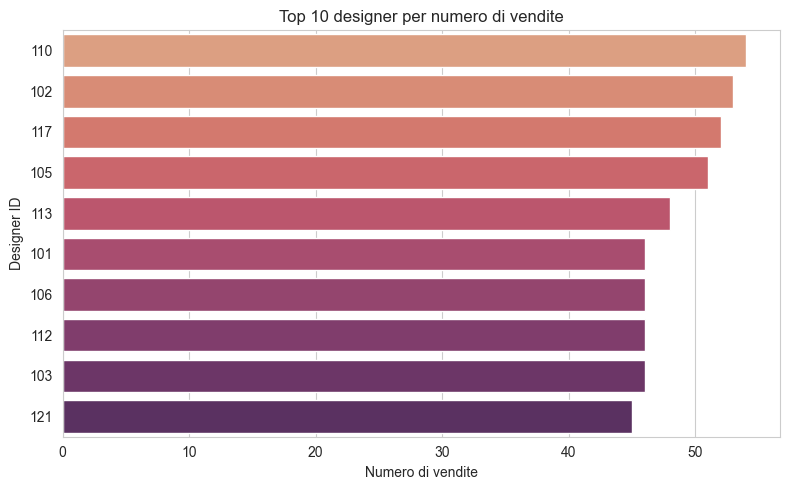

In [37]:
# Top 10 designer per numero di vendite
top_designer = df['designer_id'].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_designer.values, y=top_designer.index.astype(str), hue=top_designer.index.astype(str), palette='flare', legend=False)
plt.title('Top 10 designer per numero di vendite')
plt.xlabel('Numero di vendite')
plt.ylabel('Designer ID')
plt.tight_layout()
plt.show()

Il grafico sui top 10 designer risponde direttamente a un'altra domanda chiave del brief ("quali designer hanno avuto più successo").
Inoltre può essere utile per:

- Sapere se alcuni designer sono trainanti può essere utile per decidere dare loro più visibilità in homepage, o negoziare partnership/promozioni dedicate.
- Fornire una base per un'analisi incrociata più avanti. In seguito verranno incrociati i designer di successo con level e stars: un designer può vendere tanto ma avere recensioni basse (volume alto, qualità percepita bassa), oppure vendere poco ma con valutazioni ottime (di nicchia ma apprezzato). Questo sempre tenendo presente la domanda "cosa contribuisce al successo del prodotto?"

- Stabilire se la distribuzione è concentrata (pochi designer fanno la maggior parte delle vendite) o piuttosto uniforme tra tutti loro. Un'informazione utile anche per capire se ha senso, più avanti, creare dei cluster/segmenti anche lato designer e non solo lato utenti.

## Trend temporali
In questa fase viene studiata la distribuzione delle vendite nel tempo: andamento mensile, confronto tra anni, stagionalità e giorno della settimana più attivo.

In [40]:
# Controllo copertura temporale: verifichiamo se i mesi estremi sono completi
print("Prima data:", df['purchase_date'].min())
print("Ultima data:", df['purchase_date'].max())

Prima data: 2021-01-01 00:00:00
Ultima data: 2023-12-28 00:00:00


La copertura temporale del dataset è pressoché completa su entrambi gli estremi (1 gen 2021 – 28 dic 2023): il confronto tra anni non è distorto da mesi parziali.

In [42]:
# Vendite aggregate per mese-anno e per anno
monthly_sales = df.groupby('purchase_year_month').size()
yearly_sales = df.groupby('purchase_year').size()

print(monthly_sales.head(3))
print(monthly_sales.tail(3))
print()
print(yearly_sales)
print()
print("Crescita 2021 -> 2023:", round((yearly_sales[2023] / yearly_sales[2021] - 1) * 100, 1), "%")

purchase_year_month
2021-01    10
2021-02     7
2021-03     6
Freq: M, dtype: int64
purchase_year_month
2023-10    39
2023-11    55
2023-12    50
Freq: M, dtype: int64

purchase_year
2021     93
2022    308
2023    598
dtype: int64

Crescita 2021 -> 2023: 543.0 %


La distribuzione mensile mostra una crescita sostenuta del volume di vendite dal 2021 al 2023 (i primi mesi del 2021 registrano circa 6-10 vendite/mese, contro le 39-55 vendite/mese di fine 2023). La copertura temporale del dataset è quasi completa agli estremi (1 gen 2021 – 28 dic 2023), quindi il confronto tra anni non è distorto da mesi parziali: la crescita osservata riflette un trend reale nei dati, coerente con un marketplace in fase di espansione.

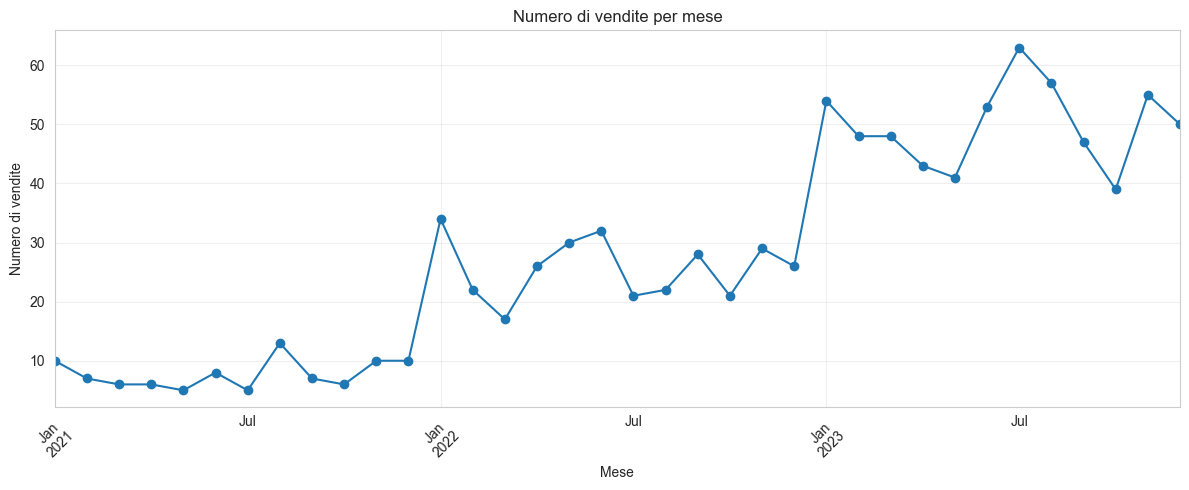

In [44]:
# Vendite per mese-anno (serie temporale continua)
monthly_sales = df.groupby('purchase_year_month').size()

plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o')
plt.title('Numero di vendite per mese')
plt.xlabel('Mese')
plt.ylabel('Numero di vendite')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

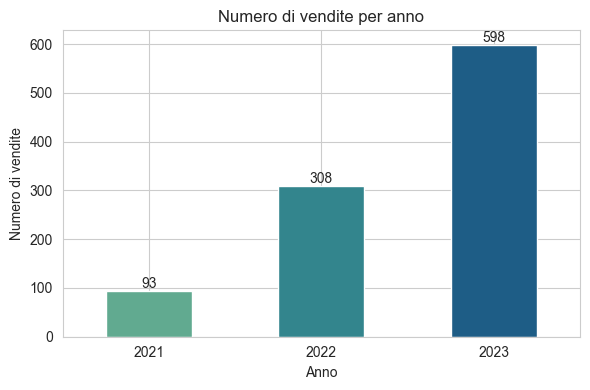

In [45]:
# Vendite totali per anno
yearly_sales = df.groupby('purchase_year').size()

plt.figure(figsize=(6, 4))
ax = yearly_sales.plot(kind='bar', color=sns.color_palette('crest', len(yearly_sales)))
ax.bar_label(ax.containers[0])
plt.title('Numero di vendite per anno')
plt.xlabel('Anno')
plt.ylabel('Numero di vendite')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Come osservato sopra c'è una crescita sostenuta del volume di vendite dal 2021 al 2023.

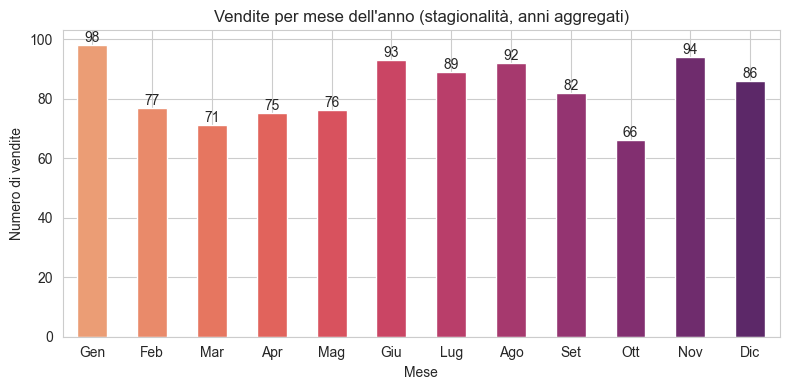

In [47]:
# Stagionalità: vendite medie per mese dell'anno (aggregando tutti gli anni insieme)
seasonal = df.groupby('purchase_month').size()

plt.figure(figsize=(8, 4))
ax = seasonal.plot(kind='bar', color=sns.color_palette('flare', 12))
ax.bar_label(ax.containers[0])
plt.title('Vendite per mese dell\'anno (stagionalità, anni aggregati)')
plt.xlabel('Mese')
plt.ylabel('Numero di vendite')
plt.xticks(ticks=range(12), labels=['Gen','Feb','Mar','Apr','Mag','Giu','Lug','Ago','Set','Ott','Nov','Dic'], rotation=0)
plt.tight_layout()
plt.show()

Il grafico di stagionalità (mese aggregando tutti gli anni) è diverso dal primo: qui sono sommati per esempio tutti i mesi di marzo degli anni 2021, 2022, 2023 insieme, per capire se ci sono mesi tipicamente più forti. Per esempio in corrispondenza dei cambi di stagione o delle festività natalizie.

Si nota per esempio un picco a gennaio, che potrebbe essere dovuto alla vendita di regali di Natale ricevuti e non graditi (o della taglia sbagliata).

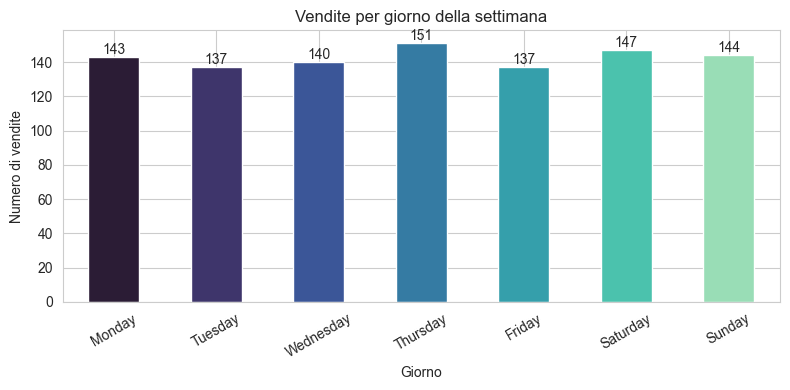

In [49]:
# Vendite per giorno della settimana
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_sales = df['purchase_weekday'].value_counts().reindex(weekday_order)

plt.figure(figsize=(8, 4))
ax = weekday_sales.plot(kind='bar', color=sns.color_palette('mako', 7))
ax.bar_label(ax.containers[0])
plt.title('Vendite per giorno della settimana')
plt.xlabel('Giorno')
plt.ylabel('Numero di vendite')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Il giorno della settimana può rivelare abitudini d'uso. 

In questo caso la distribuzione è abbastanza bilanciata, con il picco il giovedì e il minimo martedì. Sabato è al secondo posto forse perché nel finesettimana gli utenti hanno più tempo libero per fotografare/pubblicare articoli. Però nessun giorno prevale nettamente.

## Analisi incrociata: cosa contribuisce al successo del prodotto
Ora incrociamo le variabili per iniziare a rispondere alla domanda più strategica: cosa rende un prodotto/categoria/designer di successo. 
Si guarda categoria × stars, level × stars, e designer × stars/level.

In [52]:
# Valutazione media (stars) per categoria di prodotto
category_stars = df.groupby('category')['stars'].agg(['mean', 'count']).sort_values('mean', ascending=False)
category_stars['mean'] = category_stars['mean'].round(2)

category_stars

,mean,count
category,,
belt,3.10,339
shoes,3.07,165
underwear,3.05,57
bottom,2.99,135
dress,2.98,128
activewear,2.85,93
shirt,2.78,82


In questo modo si può vedere se le categorie più vendute (es. belt) sono anche quelle meglio valutate, oppure se vendono tanto ma con recensioni mediocri.

In questo caso la risposta è sì, le categorie più vendute hanno valutazioni più alte, ma di misura. Tutte le valutazioni sono da ritenere mediocri purtroppo, 3.10 di media non è ottimale.

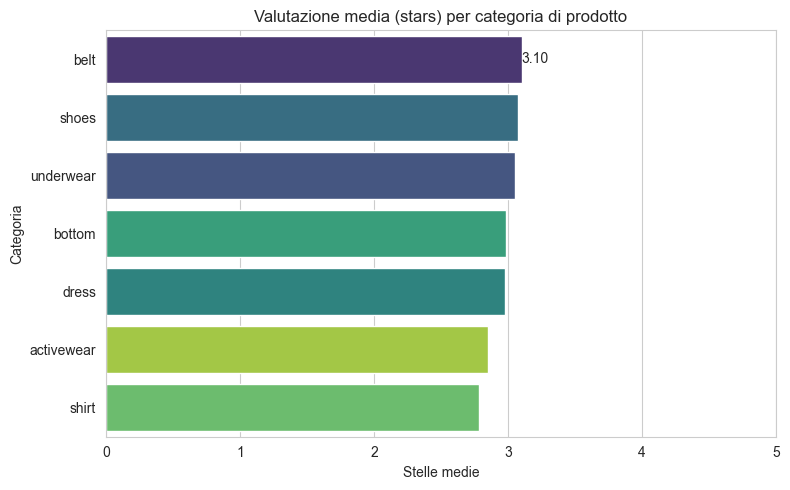

In [54]:
# Visualizzazione della valutazione media per categoria
plt.figure(figsize=(8, 5))
order = category_stars.index
ax = sns.barplot(data=df, y='category', x='stars', order=order, hue='category', palette='viridis', legend=False, errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.title('Valutazione media (stars) per categoria di prodotto')
plt.xlabel('Stelle medie')
plt.ylabel('Categoria')
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

In [55]:
# Valutazione media per fascia di prezzo (level)
level_stars = df.groupby('level')['stars'].agg(['mean', 'count']).sort_values('mean', ascending=False)
level_stars['mean'] = level_stars['mean'].round(2)

level_stars

,mean,count
level,,
average,3.05,234
cheap,3.04,332
premium,2.97,433


level_stars verifica se il prezzo è correlato alla soddisfazione.

In questo caso le valutazioni più alte sono dei prodotti average e cheap, qui in parità.

In [57]:
# Vendite e valutazione media per designer (solo i designer con più vendite, per significatività)
designer_summary = df.groupby('designer_id')['stars'].agg(['count', 'mean']).rename(columns={'count': 'n_vendite', 'mean': 'stars_medie'})
designer_summary['stars_medie'] = designer_summary['stars_medie'].round(2)
designer_summary = designer_summary.sort_values('n_vendite', ascending=False)

designer_summary.head(10)

,n_vendite,stars_medie
designer_id,,
110,54,3.19
102,53,3.02
117,52,2.90
105,51,2.78
113,48,2.92
103,46,2.91
106,46,2.91
101,46,3.02
112,46,2.83


Nel prossimo grafico, uno scatter plot, verranno visualizzate numero di vendite vs valutazione media, per designer.
I designer in alto a destra (tante vendite e stelle alte) saranno i top performer, mentre quelli in basso a destra (tante vendite ma stelle basse) sono da considerare un campanello d'allarme — vendono per notorietà/prezzo ma rischiano di deludere.

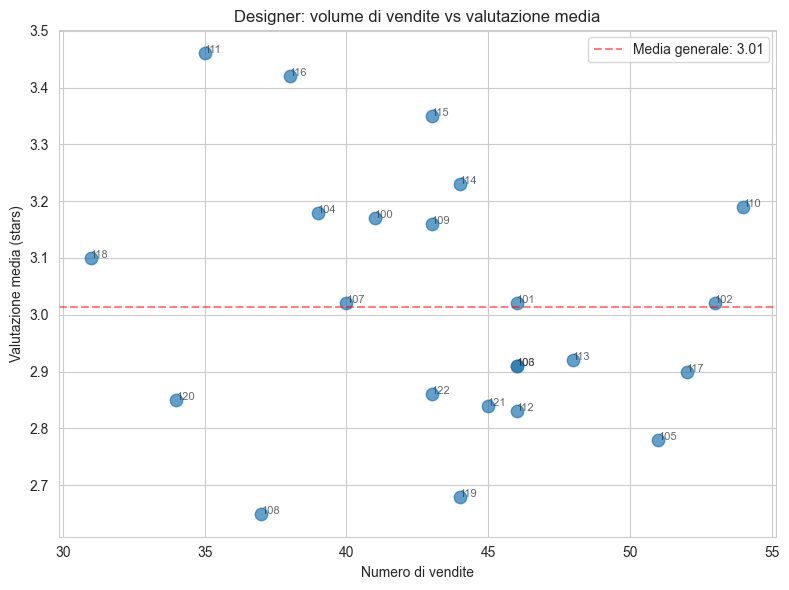

In [59]:
# Scatter: numero di vendite vs valutazione media, per designer
plt.figure(figsize=(8, 6))
plt.scatter(designer_summary['n_vendite'], designer_summary['stars_medie'], s=80, alpha=0.7)
plt.axhline(df['stars'].mean(), color='red', linestyle='--', alpha=0.5, label=f"Media generale: {df['stars'].mean():.2f}")

for idx, row in designer_summary.iterrows():
    plt.annotate(str(idx), (row['n_vendite'], row['stars_medie']), fontsize=8, alpha=0.7)

plt.title('Designer: volume di vendite vs valutazione media')
plt.xlabel('Numero di vendite')
plt.ylabel('Valutazione media (stars)')
plt.legend()
plt.tight_layout()
plt.show()

Non ci sono top performer e non c'è una tendenza evidente. Si cerca di approfondire la situazione.

In [61]:
# Correlazione tra volume di vendite e valutazione media, a livello designer
correlazione = designer_summary['n_vendite'].corr(designer_summary['stars_medie'])
print(f"Correlazione n_vendite vs stars_medie: {correlazione:.2f}")
print()
print("Range n_vendite:", designer_summary['n_vendite'].min(), "-", designer_summary['n_vendite'].max())
print("Range stars_medie:", round(designer_summary['stars_medie'].min(), 2), "-", round(designer_summary['stars_medie'].max(), 2))

Correlazione n_vendite vs stars_medie: -0.24

Range n_vendite: 31 - 54
Range stars_medie: 2.65 - 3.46


- La correlazione è -0.24, cioè debole e leggermente negativa, non c'è nessuna relazione forte tra quanto vende un designer e quanto è valutato, in linea con quello che si può osservare nello scatter.
- Il motivo per cui non si vedono "top performer" in alto a destra è nei numeri: il numero di vendite per designer varia poco (da 31 a 54, un range ristretto, con 23 designer quasi tutti concentrati tra 35 e 50) e le stelle medie oscillano solo tra 2.65 e 3.46 — molto vicine al centro della scala (3), senza nessun designer che si stacca davvero verso l'alto o il basso. Questo è coerente con quanto già notato nello Step 4: la distribuzione delle stelle è quasi uniforme (circa 20% per ogni valore da 1 a 5), quindi mediando su decine di vendite per designer, tutte le medie tendono naturalmente a convergere intorno al valore centrale (circa 3), schiacciando ogni possibile differenza tra designer.

NB: con questi dati, non è possibile identificare oggettivamente "designer di successo" basandosi solo sulle stelle.

Con la heatmap categoria×level è possibile capire se certe categorie sono vendute prevalentemente in una fascia di prezzo specifica.

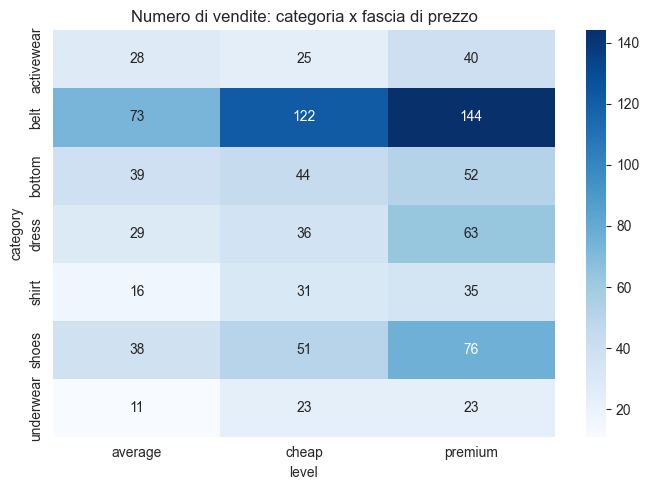

In [64]:
# Distribuzione incrociata: category x level (heatmap di conteggi)
cross_cat_level = pd.crosstab(df['category'], df['level'])

plt.figure(figsize=(7, 5))
sns.heatmap(cross_cat_level, annot=True, fmt='d', cmap='Blues')
plt.title('Numero di vendite: categoria x fascia di prezzo')
plt.tight_layout()
plt.show()

In questo caso emergono le cinture, vendute soprattutto in fascia premium.

## Analisi a livello di utente
Ora il focus si sposta dal singolo prodotto/designer al comportamento degli utenti venditori: quante vendite fa ciascuno, quale valore genera, da quanto tempo è iscritto. 

Questa è la base su cui costruire le Personas in Tableau.

Di seguito la tabella centrale di questo paragrafo: un utente per riga, con quanto vende, quanto è valutato in media, e da quanto tempo è iscritto. Da qui parte ogni ragionamento sui segmenti di utenti.

In [68]:
# Aggregazione a livello utente: numero di vendite, valutazione media, mix di fasce di prezzo, anzianità
user_summary = df.groupby('user_uuid').agg(
    n_vendite=('item_id', 'count'),
    stars_medie=('stars', 'mean'),
    tenure_medio_giorni=('account_tenure_days', 'mean')
).round(2)

user_summary = user_summary.sort_values('n_vendite', ascending=False)
user_summary.head(10)

,n_vendite,stars_medie,tenure_medio_giorni
user_uuid,,,
182,11,2.73,839.82
131,10,2.20,453.40
190,10,2.80,622.70
119,10,3.20,306.70
225,9,2.67,682.78
181,9,3.00,758.11
233,9,2.67,469.33
197,9,3.22,512.00
155,8,2.62,177.12


L'istogramma qui sotto, sul numero di vendite, mostra se ci sono pochi "power seller" e tanti utenti occasionali (distribuzione molto asimmetrica) o se le vendite sono distribuite in modo più omogeneo tra gli utenti.

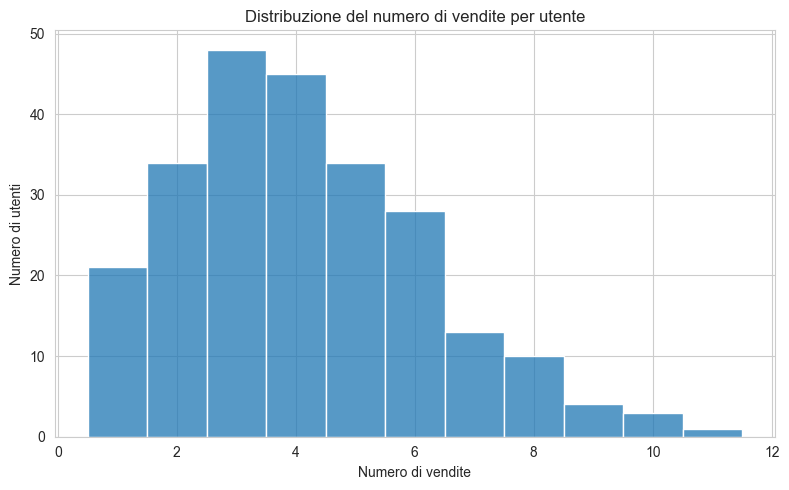

count    241.000000
mean       4.145228
std        2.089574
min        1.000000
25%        3.000000
50%        4.000000
75%        5.000000
max       11.000000
Name: n_vendite, dtype: float64


In [70]:
# Distribuzione del numero di vendite per utente
plt.figure(figsize=(8, 5))
sns.histplot(user_summary['n_vendite'], bins=range(1, user_summary['n_vendite'].max() + 2), discrete=True)
plt.title('Distribuzione del numero di vendite per utente')
plt.xlabel('Numero di vendite')
plt.ylabel('Numero di utenti')
plt.tight_layout()
plt.show()

print(user_summary['n_vendite'].describe())

non ci sono outlier estremi tipo un utente con 100 vendite che sposta tutta la media. La distribuzione è ragionevolmente omogenea.
Un ~23% degli utenti (55 su 241) ha fatto solo 1-2 vendite in tutto il periodo, mentre 18 utenti sono a 8+ vendite; quindi una polarizzazione moderata tra utenti occasionali e più attivi esiste, ma non estrema.

--------

Nella tabella sotto si cerca distinguere profili.

In [74]:
# Fascia di prezzo prevalente venduta da ciascun utente (per capire il "profilo" dell'utente)
user_level_mix = pd.crosstab(df['user_uuid'], df['level'])
user_level_mix['livello_prevalente'] = user_level_mix.idxmax(axis=1)

user_level_mix['livello_prevalente'].value_counts()

livello_prevalente
premium    94
cheap      76
average    71
Name: count, dtype: int64

È interessante che premium sia la fascia prevalente per il maggior numero di utenti, nonostante belt (tipicamente un accessorio, spesso associato a cheap) fosse la categoria più venduta in assoluto.
Il "livello_prevalente" per utente non riflette necessariamente il level più venduto in totale. Si verifica il legame tra livello prevalente per utente e valutazione media

In [76]:
# Unione livello prevalente con riepilogo utente
user_summary = user_summary.join(user_level_mix['livello_prevalente'])
user_summary.head(10)

,n_vendite,stars_medie,tenure_medio_giorni,livello_prevalente
user_uuid,,,,
182,11,2.73,839.82,premium
131,10,2.20,453.40,cheap
190,10,2.80,622.70,premium
119,10,3.20,306.70,premium
225,9,2.67,682.78,average
181,9,3.00,758.11,premium
233,9,2.67,469.33,cheap
197,9,3.22,512.00,average
155,8,2.62,177.12,cheap


In [77]:
# Verifica del legame tra livello prevalente per utente e valutazione media
user_summary.groupby('livello_prevalente')['stars_medie'].mean().round(2)

livello_prevalente
average    3.10
cheap      2.95
premium    3.05
Name: stars_medie, dtype: float64

In [78]:
# E il legame con il numero di vendite (utenti premium vendono di più o di meno?)
user_summary.groupby('livello_prevalente')['n_vendite'].mean().round(2)

livello_prevalente
average    3.83
cheap      4.26
premium    4.29
Name: n_vendite, dtype: float64

**Riassumendo**
La distribuzione del numero di vendite per utente è relativamente contenuta (media 4.1, mediana 4, range 1-11): non emergono "power seller" estremi che dominano il marketplace. Tuttavia esiste una polarizzazione moderata: circa il 23% degli utenti ha effettuato solo 1-2 vendite nel periodo osservato, mentre 18 utenti (7.5%) ne hanno effettuate 8 o più. Sul fronte del posizionamento di prezzo, gli utenti la cui fascia prevalente è premium sono il gruppo più numeroso (94 su 241, 39%), seguiti da cheap (76) e average (71).

---

Nello scatter sotto (vendite × anzianità, colorato per livello) è possibile osservare visivamente come questi profili si posizionano nello spazio. Non si tratta ancora di clustering vero e proprio.

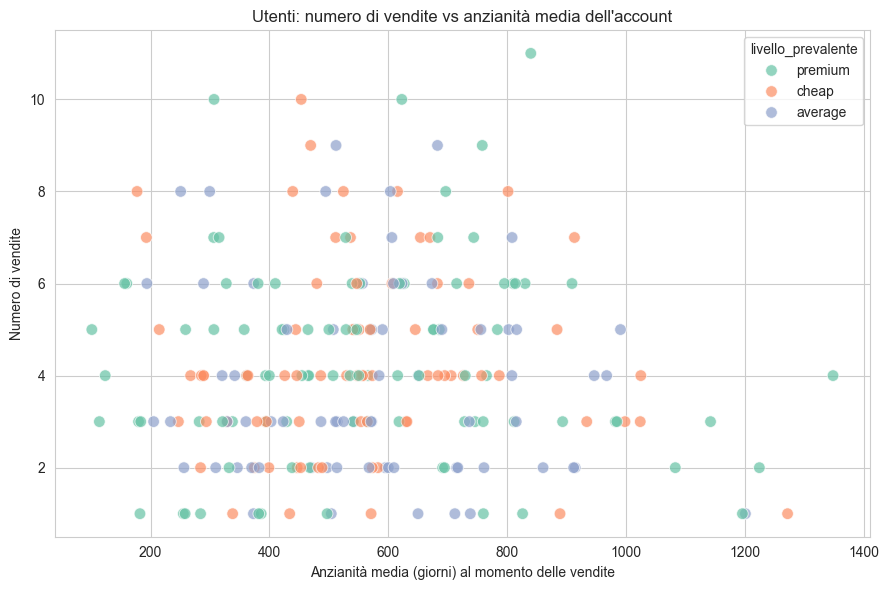

In [82]:
# Scatter: numero di vendite vs anzianità dell'account, colorato per livello prevalente
plt.figure(figsize=(9, 6))
sns.scatterplot(data=user_summary, x='tenure_medio_giorni', y='n_vendite', hue='livello_prevalente', palette='Set2', alpha=0.7, s=70)
plt.title('Utenti: numero di vendite vs anzianità media dell\'account')
plt.xlabel('Anzianità media (giorni) al momento delle vendite')
plt.ylabel('Numero di vendite')
plt.tight_layout()
plt.show()

## Riepilogo insight chiave e conclusioni

L'EDA si conclude con una vista d'insieme delle correlazioni numeriche e un riepilogo strutturato degli insight raccolti. Servirà come base sia per la presentazione sia per impostare la dashboard Tableau.

Con la heatmap di correlazione si può controlla se l'anzianità dell'account (account_tenure_days) è legata alla valutazione (stars), cioè se gli utenti veterani tendono a vendere prodotti meglio valutati.

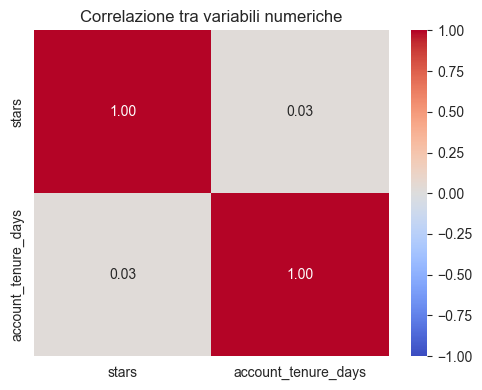

In [86]:
# Matrice di correlazione tra le variabili numeriche principali
numeric_cols = ['stars', 'account_tenure_days']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlazione tra variabili numeriche')
plt.tight_layout()
plt.show()

Non sembra esserci correlazione, 0.03 molto vicino a zero.

---

Di seguito una tabella di riepilogo utile come overview del dataset.

In [90]:
# Riepilogo sintetico dei principali KPI del dataset
riepilogo = pd.DataFrame({
    'metrica': [
        'Vendite totali', 'Utenti unici', 'Designer unici', 'Categorie',
        'Periodo coperto', 'Vendite medie per utente', 'Stelle medie generali',
        'Anzianità media account alla vendita (giorni)'
    ],
    'valore': [
        len(df), df['user_uuid'].nunique(), df['designer_id'].nunique(), df['category'].nunique(),
        f"{df['purchase_date'].min().date()} - {df['purchase_date'].max().date()}",
        round(len(df) / df['user_uuid'].nunique(), 2), round(df['stars'].mean(), 2),
        round(df['account_tenure_days'].mean(), 1)
    ]
})

riepilogo

,metrica,valore
0,Vendite totali,999
1,Utenti unici,241
2,Designer unici,23
3,Categorie,7
4,Periodo coperto,2021-01-01 - 2023-12-28
5,Vendite medie per utente,4.15
6,Stelle medie generali,3.01
7,Anzianità media account alla vendita (giorni),558.0


### Conclusioni
#### Note sulla data quality
- item_id presenta 98 valori duplicati che, dopo verifica, corrispondono ad articoli diversi (categoria/designer differenti): probabile collisione nella generazione degli ID, da non usare come chiave univoca di prodotto.
- language e country sono perfettamente ridondanti (mapping 1:1 senza eccezioni): nella realtà ci si aspetterebbe più variabilità (es. acquirenti che comprano in inglese pur non essendo madrelingua).
- La distribuzione di stars è quasi perfettamente uniforme (~20% per ogni valore 1-5): un pattern insolito per recensioni reali (di solito skewed positivamente), che suggerisce una generazione casuale nel dataset sintetico. Questo limita la possibilità di trarre insight affidabili su qualità percepita a livello di designer o categoria.

#### Insight principali
- **belt** è la categoria più venduta (34% delle vendite) — un risultato che sorprende rispetto alle aspettative di un marketplace fashion reale (dove capi come shirt/shoes sono di solito predominanti).
- Il volume di vendite mensili è cresciuto in modo marcato dal 2021 al 2023, segnale di un marketplace in espansione.
- Non emerge alcuna relazione tra volume di vendite e valutazione media a livello di designer (correlazione ≈ -0.24): con i dati attuali non è possibile identificare oggettivamente designer "di successo" basandosi sulle stelle.
- A livello utente non ci sono power seller estremi (range 1-11 vendite, media 4.1), ma esiste una polarizzazione moderata: ~23% degli utenti con 1-2 vendite contro un ~7.5% con 8+.
- Il livello di prezzo prevalente per utente si distribuisce in modo relativamente equilibrato tra premium (39%), cheap (32%) e average (29%).

#### Limiti e attenzione per la parte successiva (Tableau/ML)
- Data la natura sintetica di alcune variabili (stars uniformi, language ridondante), le personas e la segmentazione andranno costruite principalmente su n_vendite, level/livello_prevalente e account_tenure_days, che mostrano variabilità più realistica, piuttosto che su stars.
- user_summary è pronto per essere esportato e usato come base per il clustering/le personas in Tableau.

## Esportazione
Infine viene esportato user_summary, la tabella aggregata a livello utente costruita nel paragrafo "Analisi a livello utente". Nel dataset originale (df) ogni riga rappresenta una singola vendita (una riga = una transazione), ciò è utile per l'EDA, ma non è la forma giusta per segmentare gli utenti, perché lo stesso utente compare su più righe con vendite diverse.

Il dataset user_summary, invece, ha una riga per utente con le metriche che servono a distinguerli e raggrupparli in profili:
- n_vendite → quanto è attivo/prolifico
- stars_medie → qualità media percepita dei suoi prodotti
- tenure_medio_giorni → da quanto tempo è sulla piattaforma
- livello_prevalente → se vende soprattutto cheap, average o premium

Questa combinazione permette di distinguere i vari profili utente

**Cosa fa la cella successiva**
- reset_index() trasforma user_uuid da indice del dataframe a colonna vera e propria. È importante perché Tableau legge i CSV per colonne, non riconosce l'indice di pandas, quindi non facendolo si rischia di perdere l'identificativo utente in fase di import.
- to_csv(..., index=False) evita che pandas scriva un'ulteriore colonna numerica progressiva (l'indice del dataframe) che non serve e confonderebbe l'import in Tableau.
- Il file user_summary_tableau.csv verrà salvato nella stessa cartella del notebook.

In [94]:
# Esportazione di user_summary in CSV per l'importazione in Tableau
user_summary_export = user_summary.reset_index()  # riportiamo user_uuid come colonna, non come indice
user_summary_export.to_csv('user_summary_tableau.csv', index=False)

user_summary_export.head()

,user_uuid,n_vendite,stars_medie,tenure_medio_giorni,livello_prevalente
0,182,11,2.73,839.82,premium
1,131,10,2.20,453.40,cheap
2,190,10,2.80,622.70,premium
3,119,10,3.20,306.70,premium
4,225,9,2.67,682.78,average
